In [1]:
from pathlib import Path
from itertools import combinations, product
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint, adfuller
from statsmodels.stats.multitest import multipletests

OUTPUT = Path("full_pipeline_results")
OUTPUT.mkdir(exist_ok=True)
PRICE_FILE = Path("clean_prices.csv")
TRAIN_END = "2022-12-31"
VALIDATION_START = "2023-01-01"
VALIDATION_END = "2024-12-31"
TEST_START = "2025-01-01"
TOP_N_PAIRS = 4
FDR_ALPHA = 0.05
MIN_TRAIN_OBSERVATIONS = 400
MIN_TRAIN_COVERAGE = 0.95
CHECKPOINT_EVERY = 500
MAX_TICKERS = None
ENTRY_Z = 2.0
EXIT_Z = 0.0
TRANSACTION_COST = 0.001
STOP_VALUES = [None, 3.0, 3.5, 4.0]
HOLD_VALUES = [None, 60, 120, 180]
GRID = list(product(STOP_VALUES, HOLD_VALUES))
print("Parameter combinations:", len(GRID))

Parameter combinations: 16


In [2]:
if not PRICE_FILE.exists():
    raise FileNotFoundError(f"Put {PRICE_FILE.name} beside this notebook: {Path.cwd()}")
prices_raw = pd.read_csv(PRICE_FILE, index_col=0, parse_dates=True).sort_index()
prices_raw.index = pd.DatetimeIndex(prices_raw.index).normalize()
prices_raw = prices_raw.loc[~prices_raw.index.duplicated(keep="last")]
prices_raw.columns = prices_raw.columns.astype(str)
prices_raw = prices_raw.apply(pd.to_numeric, errors="coerce")
prices_raw = prices_raw.mask(prices_raw <= 0)
train_raw = prices_raw.loc[:TRAIN_END]
if len(train_raw) < MIN_TRAIN_OBSERVATIONS:
    raise ValueError("Not enough trading days in 2020–2022 training data")
coverage = train_raw.notna().mean()
eligible = coverage[(coverage >= MIN_TRAIN_COVERAGE) & (train_raw.notna().sum() >= MIN_TRAIN_OBSERVATIONS)].index.tolist()
eligible = sorted(eligible)
if MAX_TICKERS is not None:
    eligible = eligible[:MAX_TICKERS]
train_pool = train_raw[eligible]
print("Full data:", prices_raw.shape, prices_raw.index.min().date(), prices_raw.index.max().date())
print("Eligible tickers based only on training data:", len(eligible))
print("Candidate pairs:", len(eligible) * (len(eligible) - 1) // 2)
if len(eligible) < 2:
    raise ValueError("Fewer than two eligible stocks")

Full data: (1674, 485) 2020-03-19 2026-11-13
Eligible tickers based only on training data: 485
Candidate pairs: 117370


In [3]:
checkpoint = OUTPUT / "cointegration_checkpoint.csv"
all_pairs = list(combinations(eligible, 2))
run_signature = f"train_end={TRAIN_END}|min={MIN_TRAIN_OBSERVATIONS}|coverage={MIN_TRAIN_COVERAGE}|tickers={','.join(eligible)}"
signature_file = OUTPUT / "screening_signature.txt"
if checkpoint.exists():
    if not signature_file.exists() or signature_file.read_text() != run_signature:
        raise ValueError("Screening settings changed. Delete old checkpoint and signature before rerunning.")
    previous = pd.read_csv(checkpoint)
    completed = set(zip(previous["Ticker A"], previous["Ticker B"]))
    print("Resuming:", len(completed), "pairs already tested")
else:
    signature_file.write_text(run_signature)
    previous = pd.DataFrame(columns=["Ticker A", "Ticker B", "P Value", "T Statistic", "N Observations", "Error"])
    completed = set()

batch = []
start = time.monotonic()
for j, (a, b) in enumerate(all_pairs, start=1):
    if (a, b) in completed:
        continue
    pair_data = train_pool[[a, b]].dropna()
    if len(pair_data) < MIN_TRAIN_OBSERVATIONS:
        result = [a, b, np.nan, np.nan, len(pair_data), "insufficient paired observations"]
    else:
        try:
            stat, pval, _ = coint(pair_data[a].to_numpy(), pair_data[b].to_numpy(), trend="c", autolag="aic")
            result = [a, b, float(pval), float(stat), len(pair_data), ""]
        except Exception as exc:
            result = [a, b, np.nan, np.nan, len(pair_data), type(exc).__name__]
    batch.append(result)
    if len(batch) >= CHECKPOINT_EVERY or j == len(all_pairs):
        chunk = pd.DataFrame(batch, columns=previous.columns)
        chunk.to_csv(checkpoint, mode="a", header=not checkpoint.exists(), index=False)
        completed.update(zip(chunk["Ticker A"], chunk["Ticker B"]))
        batch = []
        print(f"Completed {len(completed):,}/{len(all_pairs):,} pairs; elapsed {time.monotonic()-start:.0f}s", flush=True)

if batch:
    chunk = pd.DataFrame(batch, columns=previous.columns)
    chunk.to_csv(checkpoint, mode="a", header=not checkpoint.exists(), index=False)
    completed.update(zip(chunk["Ticker A"], chunk["Ticker B"]))
    print(f"Completed {len(completed):,}/{len(all_pairs):,} pairs", flush=True)
screened = pd.read_csv(checkpoint)
if len(screened) != len(all_pairs) or screened.duplicated(["Ticker A", "Ticker B"]).any():
    raise AssertionError("Checkpoint missing or duplicating pair tests")
valid = screened["P Value"].notna()
reject, corrected, _, _ = multipletests(screened.loc[valid, "P Value"].to_numpy(), alpha=FDR_ALPHA, method="fdr_bh")
screened["BH Adjusted P"] = np.nan
screened["BH Significant"] = False
screened.loc[valid, "BH Adjusted P"] = corrected
screened.loc[valid, "BH Significant"] = reject
screened = screened.sort_values(["BH Adjusted P", "P Value", "Ticker A", "Ticker B"], na_position="last")
screened.to_csv(OUTPUT / "cointegration_all_training_pairs.csv", index=False)
print("Tests:", len(screened), "Nominal p<0.05:", int((screened["P Value"] < 0.05).sum()), "BH significant:", int(screened["BH Significant"].sum()))
display(screened.head(15))

Completed 500/117,370 pairs; elapsed 7s
Completed 1,000/117,370 pairs; elapsed 12s
Completed 1,500/117,370 pairs; elapsed 18s
Completed 2,000/117,370 pairs; elapsed 23s
Completed 2,500/117,370 pairs; elapsed 35s
Completed 3,000/117,370 pairs; elapsed 43s
Completed 3,500/117,370 pairs; elapsed 50s
Completed 4,000/117,370 pairs; elapsed 57s
Completed 4,500/117,370 pairs; elapsed 63s
Completed 5,000/117,370 pairs; elapsed 72s
Completed 5,500/117,370 pairs; elapsed 83s
Completed 6,000/117,370 pairs; elapsed 92s
Completed 6,500/117,370 pairs; elapsed 98s
Completed 7,000/117,370 pairs; elapsed 107s
Completed 7,500/117,370 pairs; elapsed 113s
Completed 8,000/117,370 pairs; elapsed 119s
Completed 8,500/117,370 pairs; elapsed 126s
Completed 9,000/117,370 pairs; elapsed 132s
Completed 9,500/117,370 pairs; elapsed 146s
Completed 10,000/117,370 pairs; elapsed 155s
Completed 10,500/117,370 pairs; elapsed 162s
Completed 11,000/117,370 pairs; elapsed 169s
Completed 11,500/117,370 pairs; elapsed 176s


,Ticker A,Ticker B,P Value,T Statistic,N Observations,Error,BH Adjusted P,BH Significant
83347,HUM,SMCI,1.670345e-07,-6.445962,703,NaN,0.019605,True
98426,MDT,VRTX,1.295451e-06,-6.045309,703,NaN,0.049397,True
79391,HAS,VRTX,1.609517e-06,-6.001740,703,NaN,0.049397,True
110052,PPL,TRV,1.683463e-06,-5.992695,703,NaN,0.049397,True
83188,HUM,INTC,2.584934e-06,-5.905810,703,NaN,0.059573,False
89716,JNJ,NUE,3.344600e-06,-5.853133,703,NaN,0.059573,False
53936,DGX,IT,3.556611e-06,-5.840512,703,NaN,0.059573,False
9925,ALGN,VRTX,4.060529e-06,-5.813228,703,NaN,0.059573,False
57432,DRI,INCY,6.877433e-06,-5.703695,703,NaN,0.080082,False
89773,JNJ,RTX,7.217516e-06,-5.693576,703,NaN,0.080082,False


In [4]:
ALLOW_EXPLORATORY_FALLBACK = False
significant_pairs = screened.loc[screened["BH Significant"]].copy()
if len(significant_pairs) == 0 and ALLOW_EXPLORATORY_FALLBACK:
    chosen = screened.loc[screened["P Value"].notna()].head(TOP_N_PAIRS).copy()
    selection_label = "EXPLORATORY: not BH-significant"
else:
    chosen = significant_pairs.copy()
    selection_label = "BH-FDR 0.05 significant"
pairs = [tuple(x) for x in chosen[["Ticker A", "Ticker B"]].to_numpy()]
chosen.to_csv(OUTPUT / "selected_training_pairs.csv", index=False)
print("Selection:", selection_label, "; Number of pairs:", len(pairs))
display(chosen)
if not pairs:
    raise ValueError("No BH-significant pairs in 2020–2022. Do not treat uncorrected p-values as significant; inspect table, or explicitly enable exploratory fallback.")

Selection: BH-FDR 0.05 significant ; Number of pairs: 4


,Ticker A,Ticker B,P Value,T Statistic,N Observations,Error,BH Adjusted P,BH Significant
83347,HUM,SMCI,1.670345e-07,-6.445962,703,NaN,0.019605,True
98426,MDT,VRTX,1.295451e-06,-6.045309,703,NaN,0.049397,True
79391,HAS,VRTX,1.609517e-06,-6.001740,703,NaN,0.049397,True
110052,PPL,TRV,1.683463e-06,-5.992695,703,NaN,0.049397,True


In [7]:
"""Shared, date-safe pairs-trading backtest engine.

The engine estimates parameters from model_train, then simulates trades on
backtest_data with signals at close and execution at a later close. It does not
perform cointegration pair discovery; that is an upstream training-only step.

Permanent re-entry rule: after any protective close (stop loss or maximum
holding period), stay flat until z crosses the zero/mean level from the
stopped side. A subsequent new threshold excursion may then open a trade.
Natural mean-reversion closes do not impose this extra lock.
"""

import numpy as np
import pandas as pd
import statsmodels.api as sm


def backtest_pair(config, train_data, test_data):
    a = config["ticker_a"]
    b = config["ticker_b"]
    entry_z = float(config["entry_z"])
    exit_z = float(config["exit_z"])
    max_days = config.get("max_holding_days")
    stop_z = config.get("stop_loss_z")
    lookback = config.get("hedge_lookback")
    cost_rate = float(config.get("transaction_cost", 0)) + float(config.get("slippage", 0))
    lag = config.get("execution_lag", 1)
    trading_days = float(config.get("trading_days", 252))

    if not isinstance(lag, int) or isinstance(lag, bool) or lag < 1:
        raise ValueError("execution_lag must be an integer >= 1")
    if entry_z <= exit_z or exit_z < 0:
        raise ValueError("Require entry_z > exit_z >= 0")
    if stop_z is not None and stop_z <= entry_z:
        raise ValueError("stop_loss_z must exceed entry_z")
    if max_days is not None and (not isinstance(max_days, int) or max_days < lag + 1):
        raise ValueError("max_holding_days must be an integer >= execution_lag + 1")
    if lookback is not None and (not isinstance(lookback, int) or lookback < 30):
        raise ValueError("hedge_lookback must be None or an integer >= 30")
    if cost_rate < 0 or trading_days <= 0:
        raise ValueError("Costs must be nonnegative and trading_days positive")

    training = train_data[[a, b]].copy().sort_index()
    testing = test_data[[a, b]].copy().sort_index()
    if len(training) < 30 or len(testing) < 3:
        raise ValueError("Need >= 30 training and >= 3 backtest observations")
    if not training.index.is_unique or not testing.index.is_unique:
        raise ValueError("Dates must be unique")
    if training.index.max() >= testing.index.min():
        raise ValueError("Training dates must all precede backtest dates")
    if training.isna().any().any() or testing.isna().any().any():
        raise ValueError("Price data must not contain missing values")
    if not np.isfinite(training.to_numpy()).all() or not np.isfinite(testing.to_numpy()).all():
        raise ValueError("Price data must be finite")
    if (training <= 0).any().any() or (testing <= 0).any().any():
        raise ValueError("Prices must be positive")

    train_fit = sm.OLS(training[a], sm.add_constant(training[b])).fit()
    alpha0 = float(train_fit.params["const"])
    beta0 = float(train_fit.params[b])
    train_spread = training[a] - alpha0 - beta0 * training[b]
    mu0 = float(train_spread.mean())
    sd0 = float(train_spread.std())
    if sd0 <= 0 or not np.isfinite(sd0):
        raise ValueError("Training spread variance must be positive")

    y = testing[a]
    x = testing[b]
    z_values = []
    beta_values = []
    if lookback is None:
        z_values = ((y - alpha0 - beta0 * x - mu0) / sd0).tolist()
        beta_values = [beta0] * len(testing)
    else:
        history = pd.concat([training, testing]).sort_index()
        for date in testing.index:
            window = history.loc[:date].tail(lookback)
            if len(window) < 30 or window[b].std() == 0:
                z_values.append(np.nan)
                beta_values.append(np.nan)
                continue
            m = sm.OLS(window[a], sm.add_constant(window[b])).fit()
            alpha = float(m.params["const"])
            beta = float(m.params[b])
            r = window[a] - alpha - beta * window[b]
            sd = float(r.std())
            z_values.append(float((r.iloc[-1] - r.mean()) / sd) if sd > 0 else np.nan)
            beta_values.append(beta)

    z = pd.Series(z_values, index=testing.index)
    betas = pd.Series(beta_values, index=testing.index)
    dates = testing.index
    n = len(testing)
    capital = float(y.iloc[0] + abs(beta0) * x.iloc[0])
    pos = 0
    pending = None
    entry_i = None
    entry_beta = None
    entry_cost = 0.0
    entry_notional = None
    gross = np.zeros(n)
    costs = np.zeros(n)
    positions = np.zeros(n, dtype=int)
    actual_betas = np.zeros(n)
    trades = []
    reentry_locked = False
    locked_direction = 0
    reentry_unlocks = []

    for i, date in enumerate(dates):
        if i > 0 and pos != 0:
            gross[i] = pos * (
                (float(y.iloc[i]) - float(y.iloc[i - 1]))
                - entry_beta * (float(x.iloc[i]) - float(x.iloc[i - 1]))
            )

        executed = False
        close_reason = None
        if pending is not None and pending[0] == i:
            if pending[1] == "open":
                pos = pending[2]
                entry_i = i
                entry_beta = pending[3]
                entry_notional = float(y.iloc[i] + abs(entry_beta) * x.iloc[i])
                entry_cost = entry_notional * cost_rate
                costs[i] += entry_cost
            else:
                close_reason = pending[2]
            pending = None
            executed = True

        if i == n - 1 and pos != 0:
            close_reason = "End of backtest"

        if close_reason is not None and pos != 0:
            exit_notional = float(y.iloc[i] + abs(entry_beta) * x.iloc[i])
            exit_cost = exit_notional * cost_rate
            costs[i] += exit_cost
            trade_gross = pos * (
                (float(y.iloc[i]) - float(y.iloc[entry_i]))
                - entry_beta * (float(x.iloc[i]) - float(x.iloc[entry_i]))
            )
            trade_net = trade_gross - entry_cost - exit_cost
            trades.append({
                "Entry Date": dates[entry_i],
                "Exit Date": date,
                "Direction": pos,
                "Hedge Ratio": entry_beta,
                "Holding Days": i - entry_i,
                "Gross P&L": trade_gross,
                "Transaction Cost": entry_cost + exit_cost,
                "Net P&L": trade_net,
                "Trade Return (%)": trade_net / entry_notional * 100,
                "Exit Reason": close_reason,
            })
            if close_reason in ("Stop loss", "Max holding"):
                reentry_locked = True
                locked_direction = pos
            pos = 0
            entry_i = None
            entry_beta = None
        elif not executed and pending is None and i + lag < n:
            zi = float(z.iloc[i])
            if pos == 0:
                if reentry_locked:
                    if np.isfinite(zi) and (
                        (locked_direction == 1 and zi >= 0)
                        or (locked_direction == -1 and zi <= 0)
                    ):
                        reentry_locked = False
                        locked_direction = 0
                        reentry_unlocks.append(date)
                elif i + lag < n - 1 and np.isfinite(zi) and np.isfinite(betas.iloc[i]):
                    if zi < -entry_z:
                        pending = (i + lag, "open", 1, float(betas.iloc[i]))
                    elif zi > entry_z:
                        pending = (i + lag, "open", -1, float(betas.iloc[i]))
            elif np.isfinite(zi):
                reason = None
                if pos == 1 and zi >= -exit_z:
                    reason = "Mean reversion"
                elif pos == -1 and zi <= exit_z:
                    reason = "Mean reversion"
                if stop_z is not None:
                    if pos == 1 and zi <= -stop_z:
                        reason = "Stop loss"
                    elif pos == -1 and zi >= stop_z:
                        reason = "Stop loss"
                if max_days is not None and i - entry_i + lag >= max_days:
                    if reason is None:
                        reason = "Max holding"
                if reason is not None:
                    pending = (i + lag, "close", reason)
            elif pos != 0 and max_days is not None and i - entry_i + lag >= max_days:
                pending = (i + lag, "close", "Max holding")

        positions[i] = pos
        actual_betas[i] = entry_beta if pos else 0

    net = gross - costs
    equity = capital + np.cumsum(net)
    daily_return = np.full(n, np.nan)
    previous_equity = np.r_[capital, equity[:-1]]
    valid = previous_equity > 0
    daily_return[valid] = net[valid] / previous_equity[valid]
    if np.any(equity <= 0):
        daily_return[:] = np.nan

    max_dd = float(np.min(equity / np.maximum.accumulate(np.r_[capital, equity])[1:] - 1))
    total_return = float(equity[-1] / capital - 1)
    annual_return = ((equity[-1] / capital) ** (trading_days / (n - 1)) - 1) if equity[-1] > 0 else np.nan
    vol_daily = float(np.std(daily_return, ddof=1)) if np.isfinite(daily_return).all() else np.nan
    vol = vol_daily * np.sqrt(trading_days)
    sharpe = float(np.mean(daily_return) / vol_daily * np.sqrt(trading_days)) if vol_daily > 0 else np.nan
    trade_log = pd.DataFrame(trades)
    win_rate = float((trade_log["Net P&L"] > 0).mean() * 100) if trades else np.nan
    avg_holding = float(trade_log["Holding Days"].mean()) if trades else np.nan
    avg_trade_return = float(trade_log["Trade Return (%)"].mean()) if trades else np.nan
    turnover = float(sum(
        (float(y.loc[row["Entry Date"]]) + abs(row["Hedge Ratio"]) * float(x.loc[row["Entry Date"]]))
        + (float(y.loc[row["Exit Date"]]) + abs(row["Hedge Ratio"]) * float(x.loc[row["Exit Date"]]))
        for row in trades
    ) / capital)
    metrics = {
        "Pair": f"{a}-{b}",
        "Total Return (%)": total_return * 100,
        "Annualized Return (%)": annual_return * 100,
        "Volatility (%)": vol * 100,
        "Sharpe": sharpe,
        "Max Drawdown (%)": max_dd * 100,
        "Trades": len(trades),
        "Win Rate (%)": win_rate,
        "Avg Holding Days": avg_holding,
        "Avg Trade Return (%)": avg_trade_return,
        "Turnover": turnover,
        "Net P&L": float(net.sum()),
    }
    daily_results = pd.DataFrame({
        "Z-score": z,
        "Signal Hedge Ratio": betas,
        "Held Hedge Ratio": actual_betas,
        "Position": positions,
        "Gross P&L": gross,
        "Transaction Cost": costs,
        "Net P&L": net,
        "Daily Return": daily_return,
        "Equity": equity,
    }, index=dates)
    if trades and not np.isclose(trade_log["Net P&L"].sum(), net.sum(), atol=1e-7):
        raise AssertionError("Trade log and daily P&L disagree")
    return {
        "metrics": metrics,
        "trade_log": trade_log,
        "daily_results": daily_results,
        "reentry_unlock_dates": reentry_unlocks,
    }

In [8]:
def history_for(pair, through):
    return prices_raw.loc[:through, list(pair)].dropna().copy()

def period_for(pair, start, end):
    return prices_raw.loc[start:end, list(pair)].dropna().copy()

def make_config(pair, stop=None, holding=None, entry=ENTRY_Z, exit_=EXIT_Z, cost=TRANSACTION_COST, lookback=None):
    return {
        "ticker_a": pair[0], "ticker_b": pair[1], "entry_z": float(entry),
        "exit_z": float(exit_), "stop_loss_z": stop, "max_holding_days": holding,
        "hedge_lookback": lookback, "transaction_cost": float(cost),
        "slippage": 0.0, "execution_lag": 1, "trading_days": 252
    }

def run_period(pair, stop, holding, phase, entry=ENTRY_Z, exit_=EXIT_Z, cost=TRANSACTION_COST, lookback=None):
    if phase == "validation":
        train = history_for(pair, TRAIN_END)
        test = period_for(pair, VALIDATION_START, VALIDATION_END)
    elif phase == "final":
        train = history_for(pair, VALIDATION_END)
        test = period_for(pair, TEST_START, str(prices_raw.index.max().date()))
    else:
        raise ValueError("phase must be validation or final")
    if len(test) < 3:
        raise ValueError(f"Insufficient test data for {pair} / {phase}")
    return backtest_pair(make_config(pair, stop, holding, entry, exit_, cost, lookback), train, test)

def config_label(stop, holding):
    return f"Stop={stop}, Hold={holding}"

print("Selected pairs:", pairs)
print("Validation end:", VALIDATION_END, "; Final test starts:", TEST_START)

Selected pairs: [('HUM', 'SMCI'), ('MDT', 'VRTX'), ('HAS', 'VRTX'), ('PPL', 'TRV')]
Validation end: 2024-12-31 ; Final test starts: 2025-01-01


/var/folders/55/bpnz_y1d7h983b05s9zgmpbw0000gn/T/ipykernel_1889/1625822464.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  spread_info.append({"Pair": "-".join(pair), "Alpha": alpha, "Beta": beta, "Mean Spread": float(spread.mean()), "Std Spread": float(spread.std()), "ADF p-value": float(adfuller(spread, autolag="AIC")[1])})


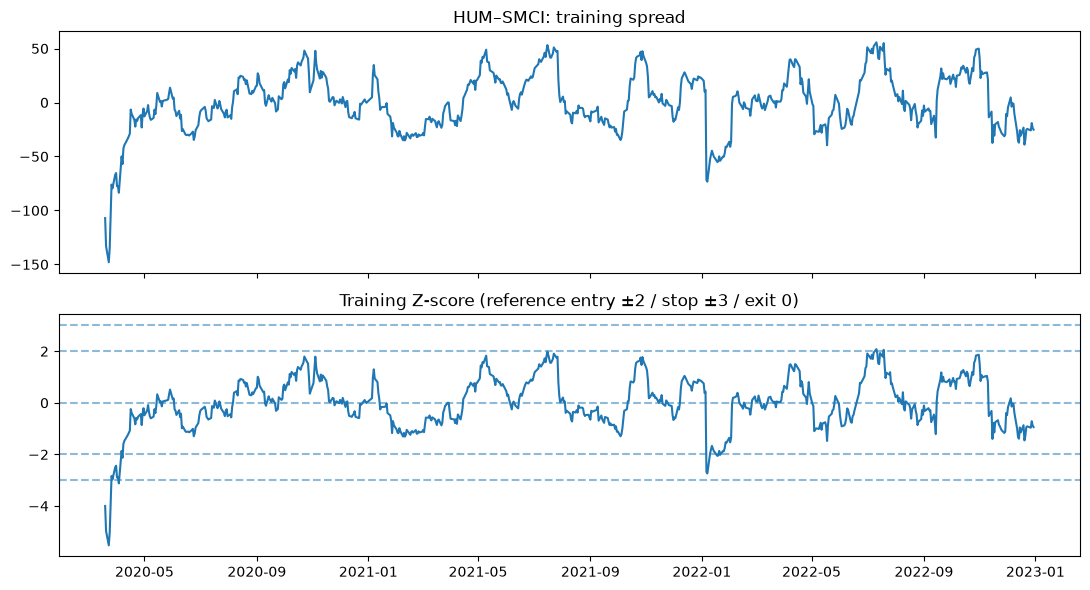

/var/folders/55/bpnz_y1d7h983b05s9zgmpbw0000gn/T/ipykernel_1889/1625822464.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  spread_info.append({"Pair": "-".join(pair), "Alpha": alpha, "Beta": beta, "Mean Spread": float(spread.mean()), "Std Spread": float(spread.std()), "ADF p-value": float(adfuller(spread, autolag="AIC")[1])})
/var/folders/55/bpnz_y1d7h983b05s9zgmpbw0000gn/T/ipykernel_1889/1625822464.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switc

,Pair,Alpha,Beta,Mean Spread,Std Spread,ADF p-value
0,HUM-SMCI,306.7252,25.5102,0.0,26.7701,0.0
1,MDT-VRTX,155.8401,-0.2686,0.0,6.7727,0.0
2,HAS-VRTX,115.1950,-0.1859,-0.0,6.6058,0.0
3,PPL-TRV,14.9212,0.0615,0.0,1.0950,0.0


In [9]:
import statsmodels.api as sm
spread_info = []
for pair in pairs:
    train = history_for(pair, TRAIN_END)
    fit = sm.OLS(train[pair[0]], sm.add_constant(train[pair[1]])).fit()
    alpha = float(fit.params["const"])
    beta = float(fit.params[pair[1]])
    spread = train[pair[0]] - alpha - beta * train[pair[1]]
    z = (spread - spread.mean()) / spread.std()
    spread_info.append({"Pair": "-".join(pair), "Alpha": alpha, "Beta": beta, "Mean Spread": float(spread.mean()), "Std Spread": float(spread.std()), "ADF p-value": float(adfuller(spread, autolag="AIC")[1])})
    if pair == pairs[0]:
        fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
        axes[0].plot(spread.index, spread.values)
        axes[0].set_title(f"{pair[0]}–{pair[1]}: training spread")
        axes[1].plot(z.index, z.values)
        for threshold in [-3, -2, 0, 2, 3]:
            axes[1].axhline(threshold, ls="--", alpha=0.5)
        axes[1].set_title("Training Z-score (reference entry ±2 / stop ±3 / exit 0)")
        plt.tight_layout()
        plt.show()
spread_parameters = pd.DataFrame(spread_info)
spread_parameters.to_csv(OUTPUT / "training_spread_parameters.csv", index=False)
display(spread_parameters.round(4))

In [10]:
validation_runs = {}
validation_rows = []
for pair in pairs:
    for stop, holding in GRID:
        result = run_period(pair, stop, holding, "validation")
        validation_runs[(pair, stop, holding)] = result
        validation_rows.append({**result["metrics"], "Config": config_label(stop, holding), "Stop": stop, "Hold": holding})
    print("Validation finished:", pair, flush=True)
validation_table = pd.DataFrame(validation_rows)
validation_table.to_csv(OUTPUT / "validation_16_grid_per_pair.csv", index=False)
assert len(validation_runs) == len(pairs)*16
display(validation_table[["Pair", "Config", "Total Return (%)", "Sharpe", "Max Drawdown (%)", "Trades"]].round(3))

Validation finished: ('HUM', 'SMCI')
Validation finished: ('MDT', 'VRTX')
Validation finished: ('HAS', 'VRTX')
Validation finished: ('PPL', 'TRV')


,Pair,Config,Total Return (%),Sharpe,Max Drawdown (%),Trades
0,HUM-SMCI,"Stop=None, Hold=None",-114.333,NaN,-407.331,1
1,HUM-SMCI,"Stop=None, Hold=60",-2.977,-0.119,-17.063,1
2,HUM-SMCI,"Stop=None, Hold=120",-70.026,-1.400,-71.799,1
3,HUM-SMCI,"Stop=None, Hold=180",-68.236,0.875,-99.175,1
4,HUM-SMCI,"Stop=3.0, Hold=None",-6.879,-0.473,-12.387,1
...,...,...,...,...,...,...
59,PPL-TRV,"Stop=3.5, Hold=180",3.286,0.361,-7.118,3
60,PPL-TRV,"Stop=4.0, Hold=None",12.660,0.688,-9.036,3
61,PPL-TRV,"Stop=4.0, Hold=60",7.917,0.687,-7.118,3
62,PPL-TRV,"Stop=4.0, Hold=120",2.237,0.186,-8.980,3


In [11]:
pair = ("HUM", "SMCI")

result = validation_runs[(pair, None, None)]

daily = result["daily_results"]
trades = result["trade_log"]

initial_capital = daily["Equity"].iloc[0] - daily["Net P&L"].iloc[0]

print("Initial capital:", initial_capital)
print("Minimum equity:", daily["Equity"].min())
print("Minimum equity date:", daily["Equity"].idxmin())
print("Final equity:", daily["Equity"].iloc[-1])
print("Days below zero:", (daily["Equity"] <= 0).sum())

display(trades)
display(daily.nsmallest(10, "Equity"))

Initial capital: 693.7182890913863
Minimum equity: -2266.042929351303
Minimum equity date: 2024-03-13 00:00:00
Final equity: -99.43104918626045
Days below zero: 231


,Entry Date,Exit Date,Direction,Hedge Ratio,Holding Days,Gross P&L,Transaction Cost,Net P&L,Trade Return (%),Exit Reason
0,2023-01-10,2024-12-31,1,25.510192,496,-791.462356,1.686982,-793.149338,-119.884426,End of backtest


,Z-score,Signal Hedge Ratio,Held Hedge Ratio,Position,Gross P&L,Transaction Cost,Net P&L,Daily Return,Equity
Date,,,,,,,,,
2024-03-13,-112.217538,25.510192,25.510192,1,-63.905614,0.0,-63.905614,NaN,-2266.042929
2024-03-12,-109.830338,25.510192,25.510192,1,-212.960325,0.0,-212.960325,NaN,-2202.137315
2024-03-07,-109.681425,25.510192,25.510192,1,-87.854543,0.0,-87.854543,NaN,-2198.150905
2024-03-08,-107.848814,25.510192,25.510192,1,49.059226,0.0,49.059226,NaN,-2149.091678
2024-03-14,-106.561183,25.510192,25.510192,1,151.421283,0.0,151.421283,NaN,-2114.621646
2024-03-06,-106.399611,25.510192,25.510192,1,-85.282564,0.0,-85.282564,NaN,-2110.296361
2024-03-05,-103.213874,25.510192,25.510192,1,-50.672744,0.0,-50.672744,NaN,-2025.013797
2024-03-11,-101.875187,25.510192,25.510192,1,159.914687,0.0,159.914687,NaN,-1989.176991
2024-03-04,-101.320989,25.510192,25.510192,1,-435.787943,0.0,-435.787943,NaN,-1974.341053


,HUM,SMCI
Date,,
2022-12-01,524.885742,9.051
2022-12-02,523.363831,8.670
2022-12-05,523.976440,8.331
2022-12-06,522.952148,8.628
2022-12-07,525.661011,8.610
2022-12-08,523.918945,8.561
2022-12-09,510.575897,8.402
2022-12-12,507.292725,8.916
2022-12-13,500.659607,9.001


,HUM,SMCI
Date,,
2024-02-01,363.014648,58.349998
2024-02-02,365.960724,57.963001
2024-02-05,348.718903,66.334999
2024-02-06,353.867310,68.158997
2024-02-07,356.011719,68.360001
2024-02-08,355.267883,69.800003
2024-02-09,357.663422,74.028999
2024-02-12,356.562256,77.301003
2024-02-13,352.061066,79.149002


array([<Axes: title={'center': 'HUM Adjusted Price'}, xlabel='Date'>,
       <Axes: title={'center': 'SMCI Adjusted Price'}, xlabel='Date'>],
      dtype=object)

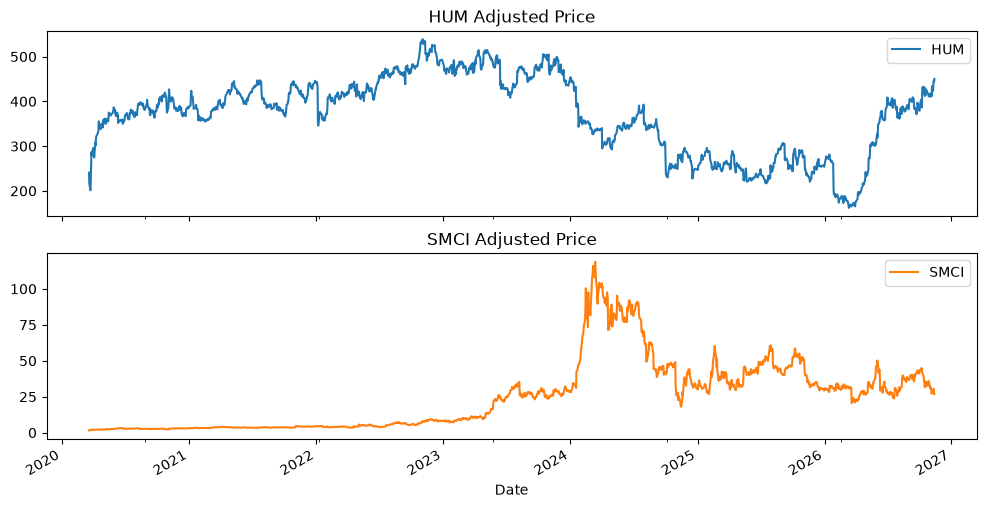

In [12]:
pair_prices = prices_raw[["HUM", "SMCI"]]

display(pair_prices.loc["2022-12":"2023-02"].head(15))
display(pair_prices.loc["2024-02":"2024-04"].head(15))

pair_prices.plot(
    subplots=True,
    figsize=(12, 6),
    title=["HUM Adjusted Price", "SMCI Adjusted Price"]
)

In [13]:
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import pairs_backtest_engine

importlib.reload(pairs_backtest_engine)
backtest_pair = pairs_backtest_engine.backtest_pair

prices = pd.read_csv("clean_prices.csv", index_col=0, parse_dates=True).sort_index()
prices = prices[["HUM", "SMCI"]].replace([np.inf, -np.inf], np.nan).dropna()

print("Data:", prices.index.min(), "to", prices.index.max(), "rows:", len(prices))
print("Engine:", Path(pairs_backtest_engine.__file__).resolve())
assert prices.index.min() <= pd.Timestamp("2020-03-19")
assert prices.index.max() >= pd.Timestamp("2026-01-01")

Data: 2020-03-19 00:00:00 to 2026-11-13 00:00:00 rows: 1674
Engine: /Users/liusiming/pairs-trading-strategy/pairs_backtest_engine.py


In [14]:
stop_grid = [None, 3.0, 3.5, 4.0]
holding_grid = [None, 60, 120, 180]
configs = list(product(stop_grid, holding_grid))
years = [2023, 2024, 2025, 2026]

base_config = {
    "ticker_a": "HUM",
    "ticker_b": "SMCI",
    "p_value_threshold": 0.05,
    "fdr_threshold": 0.05,
    "entry_z": 2.0,
    "exit_z": 0.0,
    "hedge_lookback": None,
    "stop_loss_z": None,
    "max_holding_days": None,
    "transaction_cost": 0.001,
    "slippage": 0.0,
    "execution_lag": 1,
    "trading_days": 252
}

assert len(configs) == 16

In [15]:
runs = {}
records = []
for year in years:
    model_train = prices.loc[f"{year-3}-01-01":f"{year-1}-12-31"]
    test_period = prices.loc[f"{year}-01-01":f"{year}-12-31"]
    if len(model_train) < 100 or len(test_period) < 50:
        raise ValueError(f"Insufficient data for {year}: train={len(model_train)}, test={len(test_period)}")
    for stop, hold in configs:
        config = dict(base_config)
        config["stop_loss_z"] = stop
        config["max_holding_days"] = hold
        result = backtest_pair(config, model_train, test_period)
        runs[(year, stop, hold)] = result
        daily = result["daily_results"]
        m = result["metrics"]
        equity = daily["Equity"]
        breached = equity <= 0
        initial_capital = float(equity.iloc[0] - daily["Net P&L"].iloc[0])
        records.append({
            "Year": year,
            "Stop": stop,
            "Hold": hold,
            "Config": f"Stop={stop}, Hold={hold}",
            "Total Return (%)": m["Total Return (%)"],
            "Sharpe": m["Sharpe"],
            "Max Drawdown (%)": m["Max Drawdown (%)"],
            "Trades": m["Trades"],
            "Initial Capital": initial_capital,
            "Minimum Equity": equity.min(),
            "Days Equity <= 0": int(breached.sum()),
            "First Equity Breach": equity.index[breached.argmax()] if breached.any() else pd.NaT,
            "Minimum Z-score": daily["Z-score"].min(),
            "Maximum Z-score": daily["Z-score"].max(),
            "Solvency Pass": not breached.any()
        })
    partial = pd.DataFrame(records)
    this_year = partial.loc[partial["Year"] == year].copy()
    this_year = this_year.sort_values(["Solvency Pass", "Max Drawdown (%)"], ascending=[False, False])
    print(f"\n{year}: completed 16 / 16 configs, train rows={len(model_train)}, test rows={len(test_period)}")
    display(this_year[["Config", "Total Return (%)", "Sharpe", "Max Drawdown (%)", "Trades", "Minimum Equity", "Days Equity <= 0", "Solvency Pass"]].round(3).reset_index(drop=True))

results = pd.DataFrame(records)
print("\nCompleted:", len(results), "backtests")


2023: completed 16 / 16 configs, train rows=703, test rows=250


,Config,Total Return (%),Sharpe,Max Drawdown (%),Trades,Minimum Equity,Days Equity <= 0,Solvency Pass
0,"Stop=3.0, Hold=None",-6.879,-0.671,-12.387,1,645.998,0,True
1,"Stop=3.0, Hold=60",-6.879,-0.671,-12.387,1,645.998,0,True
2,"Stop=3.0, Hold=120",-6.879,-0.671,-12.387,1,645.998,0,True
3,"Stop=3.0, Hold=180",-6.879,-0.671,-12.387,1,645.998,0,True
4,"Stop=3.5, Hold=None",-6.968,-0.644,-13.297,1,639.284,0,True
5,"Stop=3.5, Hold=60",-6.968,-0.644,-13.297,1,639.284,0,True
6,"Stop=3.5, Hold=120",-6.968,-0.644,-13.297,1,639.284,0,True
7,"Stop=3.5, Hold=180",-6.968,-0.644,-13.297,1,639.284,0,True
8,"Stop=None, Hold=60",-2.977,-0.169,-17.063,1,611.520,0,True
9,"Stop=4.0, Hold=None",-11.959,-1.047,-17.166,1,610.758,0,True



2024: completed 16 / 16 configs, train rows=753, test rows=252


,Config,Total Return (%),Sharpe,Max Drawdown (%),Trades,Minimum Equity,Days Equity <= 0,Solvency Pass
0,"Stop=3.0, Hold=None",-1.872,-0.831,-2.777,1,502.176,0,True
1,"Stop=3.0, Hold=60",-1.872,-0.831,-2.777,1,502.176,0,True
2,"Stop=3.0, Hold=120",-1.872,-0.831,-2.777,1,502.176,0,True
3,"Stop=3.0, Hold=180",-1.872,-0.831,-2.777,1,502.176,0,True
4,"Stop=3.5, Hold=None",-9.791,-1.024,-11.691,1,456.134,0,True
5,"Stop=3.5, Hold=60",-9.791,-1.024,-11.691,1,456.134,0,True
6,"Stop=3.5, Hold=120",-9.791,-1.024,-11.691,1,456.134,0,True
7,"Stop=3.5, Hold=180",-9.791,-1.024,-11.691,1,456.134,0,True
8,"Stop=4.0, Hold=None",-9.791,-1.024,-11.691,1,456.134,0,True
9,"Stop=4.0, Hold=60",-9.791,-1.024,-11.691,1,456.134,0,True



2025: completed 16 / 16 configs, train rows=753, test rows=250


,Config,Total Return (%),Sharpe,Max Drawdown (%),Trades,Minimum Equity,Days Equity <= 0,Solvency Pass
0,"Stop=None, Hold=60",2.133,0.209,-16.046,1,289.154,0,True
1,"Stop=3.0, Hold=60",2.133,0.209,-16.046,1,289.154,0,True
2,"Stop=3.5, Hold=60",2.133,0.209,-16.046,1,289.154,0,True
3,"Stop=4.0, Hold=60",2.133,0.209,-16.046,1,289.154,0,True
4,"Stop=None, Hold=120",2.877,0.243,-21.824,1,269.253,0,True
5,"Stop=None, Hold=180",7.189,0.375,-21.824,1,269.253,0,True
6,"Stop=3.0, Hold=120",2.877,0.243,-21.824,1,269.253,0,True
7,"Stop=3.0, Hold=180",7.189,0.375,-21.824,1,269.253,0,True
8,"Stop=3.5, Hold=120",2.877,0.243,-21.824,1,269.253,0,True
9,"Stop=3.5, Hold=180",7.189,0.375,-21.824,1,269.253,0,True



2026: completed 16 / 16 configs, train rows=752, test rows=219


,Config,Total Return (%),Sharpe,Max Drawdown (%),Trades,Minimum Equity,Days Equity <= 0,Solvency Pass
0,"Stop=None, Hold=None",54.967,2.408,-15.387,1,268.255,0,True
1,"Stop=None, Hold=60",7.530,0.607,-15.387,1,268.255,0,True
2,"Stop=None, Hold=120",54.967,2.408,-15.387,1,268.255,0,True
3,"Stop=None, Hold=180",54.967,2.408,-15.387,1,268.255,0,True
4,"Stop=3.0, Hold=None",54.967,2.408,-15.387,1,268.255,0,True
5,"Stop=3.0, Hold=60",7.530,0.607,-15.387,1,268.255,0,True
6,"Stop=3.0, Hold=120",54.967,2.408,-15.387,1,268.255,0,True
7,"Stop=3.0, Hold=180",54.967,2.408,-15.387,1,268.255,0,True
8,"Stop=3.5, Hold=None",54.967,2.408,-15.387,1,268.255,0,True
9,"Stop=3.5, Hold=60",7.530,0.607,-15.387,1,268.255,0,True



Completed: 64 backtests


In [16]:
risk_summary = results.groupby("Config", as_index=False).agg(
    Solvent_Years=("Solvency Pass", "sum"),
    Breach_Days=("Days Equity <= 0", "sum"),
    Worst_Annual_DD=("Max Drawdown (%)", "min"),
    Mean_Annual_Return=("Total Return (%)", "mean"),
    Median_Annual_Return=("Total Return (%)", "median"),
    Total_Trades=("Trades", "sum")
)
risk_summary = risk_summary.sort_values(
    ["Solvent_Years", "Worst_Annual_DD", "Mean_Annual_Return"],
    ascending=[False, False, False]
).reset_index(drop=True)
display(risk_summary.round(3))

,Config,Solvent_Years,Breach_Days,Worst_Annual_DD,Mean_Annual_Return,Median_Annual_Return,Total_Trades
0,"Stop=3.0, Hold=60",4,0,-16.046,0.228,0.131,4
1,"Stop=3.5, Hold=60",4,0,-16.046,-1.774,-2.418,4
2,"Stop=4.0, Hold=60",4,0,-17.166,-3.022,-3.829,4
3,"Stop=3.0, Hold=180",4,0,-21.824,13.351,2.659,4
4,"Stop=3.0, Hold=120",4,0,-21.824,12.273,0.503,4
5,"Stop=3.5, Hold=180",4,0,-21.824,11.349,0.110,4
6,"Stop=3.5, Hold=120",4,0,-21.824,10.271,-2.046,4
7,"Stop=4.0, Hold=180",4,0,-21.824,10.102,-1.301,4
8,"Stop=4.0, Hold=120",4,0,-21.824,9.023,-3.457,4
9,"Stop=3.5, Hold=None",4,0,-31.407,8.722,-5.144,4


In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pairs_backtest_engine import backtest_pair

PRICE_FILE = Path("clean_prices.csv")
if not PRICE_FILE.exists():
    raise FileNotFoundError(f"Missing {PRICE_FILE.resolve()}. Place this notebook beside the original full clean_prices.csv")
prices = pd.read_csv(PRICE_FILE, index_col=0, parse_dates=True).sort_index()
prices = prices.loc[~prices.index.duplicated(keep="last")]
prices.columns = prices.columns.astype(str)
prices = prices.apply(pd.to_numeric, errors="coerce").mask(lambda x: x <= 0)
THREE_YEAR_PAIRS = [("HUM","SMCI"),("MDT","VRTX"),("HAS","VRTX"),("PPL","TRV")]
FIVE_YEAR_PAIRS = [("MA","PH"),("CHRW","WEC"),("AVGO","FIX"),("CRH","MA")]
all_tickers = set(sum((list(p) for p in THREE_YEAR_PAIRS + FIVE_YEAR_PAIRS), []))
missing = sorted(all_tickers.difference(prices.columns))
if missing:
    raise ValueError(f"The clean_prices.csv does not have the full 8-pair stock universe. Missing: {missing}. Do NOT use mock/partial CSV.")
print("Full data shape:", prices.shape)
print("Available dates:", prices.index.min().date(), "to", prices.index.max().date())
print("3Y selected:", THREE_YEAR_PAIRS)
print("5Y selected:", FIVE_YEAR_PAIRS)

Full data shape: (1674, 485)
Available dates: 2020-03-19 to 2026-11-13
3Y selected: [('HUM', 'SMCI'), ('MDT', 'VRTX'), ('HAS', 'VRTX'), ('PPL', 'TRV')]
5Y selected: [('MA', 'PH'), ('CHRW', 'WEC'), ('AVGO', 'FIX'), ('CRH', 'MA')]


In [18]:
GROUPS = {"3Y-selected": (3, THREE_YEAR_PAIRS), "5Y-selected": (5, FIVE_YEAR_PAIRS)}
TEST_YEARS = (2025, 2026)
RULES = {"Baseline": (None, None), "Stop3_Hold60": (3.0, 60)}
BASE = dict(entry_z=2.0,exit_z=0.0,hedge_lookback=None,
            transaction_cost=0.001,slippage=0.0,execution_lag=1,trading_days=252)

def record_result(group, pair, rule, period, kind, result):
    m = result["metrics"]
    d = result["daily_results"]
    equity = d["Equity"]
    breached = bool((equity <= 0).any())
    return {"Group": group, "Pair": "–".join(pair), "Rule": rule,
            "Period": str(period), "Experiment": kind,
            "Return (%)": m["Total Return (%)"], "Sharpe": m["Sharpe"],
            "Max DD (%)": m["Max Drawdown (%)"], "Trades": m["Trades"],
            "Minimum Equity": float(equity.min()), "Solvency Pass": not breached,
            "End Equity": float(equity.iloc[-1])}

records = []
errors = []
run_objects = {}

def execute(group, pair, rule, period, kind, training, testing, stop, hold):
    a,b = pair
    both = [a,b]
    tr,ts = training[both].dropna(),testing[both].dropna()
    if len(tr) < 300 or len(ts) < 40:
        errors.append(dict(Group=group,Pair=f"{a}–{b}",Period=str(period),Rule=rule,Experiment=kind,Reason=f"Missing observations: train {len(tr)}, test {len(ts)}"))
        return
    cfg = {**BASE,"ticker_a":a,"ticker_b":b,"stop_loss_z":stop,"max_holding_days":hold}
    try:
        run = backtest_pair(cfg,tr,ts)
        key=(kind,group,f"{a}–{b}",str(period),rule)
        run_objects[key]=run
        records.append(record_result(group,pair,rule,period,kind,run))
    except Exception as exc:
        errors.append(dict(Group=group,Pair=f"{a}–{b}",Period=str(period),Rule=rule,Experiment=kind,Reason=repr(exc)))

In [19]:
for year in TEST_YEARS:
    test = prices.loc[f"{year}-01-01":f"{year}-12-31"]
    for group,(window,pairs) in GROUPS.items():
        start, end = year - window, year - 1
        train = prices.loc[f"{start}-01-01":f"{end}-12-31"]
        for pair in pairs:
            for rule,(stop,hold) in RULES.items():
                execute(group,pair,rule,year,"Rolling",train,test,stop,hold)
    current = pd.DataFrame(records)
    print(f"{year}: completed {len(current[current.Period.eq(str(year)) & current.Experiment.eq('Rolling')])} rolling runs")
    subset = current[(current.Period == str(year)) & (current.Experiment == "Rolling")]
    display(subset[["Group","Pair","Rule","Return (%)","Max DD (%)","Sharpe","Trades","Solvency Pass"]].round(2).sort_values(["Rule","Return (%)"],ascending=[True,False]))

results = pd.DataFrame(records)
if errors:
    print("Skipped/failed cases:")
    display(pd.DataFrame(errors))

2025: completed 16 rolling runs


,Group,Pair,Rule,Return (%),Max DD (%),Sharpe,Trades,Solvency Pass
12,5Y-selected,AVGO–FIX,Baseline,18.76,-13.16,0.81,3,True
14,5Y-selected,CRH–MA,Baseline,8.51,-8.09,0.75,4,True
10,5Y-selected,CHRW–WEC,Baseline,8.33,-10.85,0.61,3,True
8,5Y-selected,MA–PH,Baseline,5.23,-6.30,0.46,2,True
6,3Y-selected,PPL–TRV,Baseline,3.29,-9.23,0.38,1,True
0,3Y-selected,HUM–SMCI,Baseline,-3.32,-31.41,0.12,1,True
2,3Y-selected,MDT–VRTX,Baseline,-6.36,-26.26,-0.23,1,True
4,3Y-selected,HAS–VRTX,Baseline,-6.83,-18.47,-0.30,1,True
3,3Y-selected,MDT–VRTX,Stop3_Hold60,11.95,-4.55,1.00,1,True
5,3Y-selected,HAS–VRTX,Stop3_Hold60,7.30,-8.07,0.61,1,True


2026: completed 16 rolling runs


,Group,Pair,Rule,Return (%),Max DD (%),Sharpe,Trades,Solvency Pass
16,3Y-selected,HUM–SMCI,Baseline,54.97,-15.39,2.41,1,True
26,5Y-selected,CHRW–WEC,Baseline,19.60,-17.26,0.86,1,True
18,3Y-selected,MDT–VRTX,Baseline,13.04,-5.03,1.49,2,True
24,5Y-selected,MA–PH,Baseline,6.80,-13.78,0.52,1,True
30,5Y-selected,CRH–MA,Baseline,-3.13,-11.73,-0.16,2,True
28,5Y-selected,AVGO–FIX,Baseline,-3.88,-49.50,0.25,1,True
22,3Y-selected,PPL–TRV,Baseline,-12.80,-13.72,-1.34,1,True
20,3Y-selected,HAS–VRTX,Baseline,-28.77,-38.11,-1.11,1,True
19,3Y-selected,MDT–VRTX,Stop3_Hold60,10.27,-5.03,1.26,2,True
17,3Y-selected,HUM–SMCI,Stop3_Hold60,7.53,-15.39,0.61,1,True


In [20]:
for rule in RULES:
    sub = results[(results.Experiment == "Rolling") & (results.Rule == rule)].copy()
    pivot = sub.pivot(index=["Group","Pair"],columns="Period",values="Return (%)")
    p = pivot.reindex(columns=["2025","2026"])
    p["Both Years Profitable"] = p[["2025","2026"]].gt(0).all(axis=1)
    p["Profitable Years"] = p[["2025","2026"]].gt(0).sum(axis=1)
    p["Worst Year (%)"] = p[["2025","2026"]].min(axis=1)
    p["Mean Annual (%)"] = p[["2025","2026"]].mean(axis=1)
    p["Compounded 2Y (%)"] = ((1+p["2025"]/100)*(1+p["2026"]/100)-1)*100
    p["Warning"] = np.where(p[["2025","2026"]].le(-100).any(axis=1),"Return ≤ -100%","")
    p = p.sort_values(["Both Years Profitable","Compounded 2Y (%)"],ascending=False)
    print("RULE:",rule)
    display(p.round(2))
    print("By selection group (descriptive only; four pairs per group):")
    print(p.groupby(level="Group")[["Profitable Years","Compounded 2Y (%)","Worst Year (%)"]].mean().round(2))
    print("Solvency check:")
    display(sub.groupby(["Group","Pair"])["Solvency Pass"].all().rename("All Years Solvent"))

RULE: Baseline


Period                 2025   2026  Both Years Profitable  Profitable Years  \
Group       Pair                                                              
5Y-selected CHRW–WEC   8.33  19.60                   True                 2   
            MA–PH      5.23   6.80                   True                 2   
3Y-selected HUM–SMCI  -3.32  54.97                  False                 1   
5Y-selected AVGO–FIX  18.76  -3.88                  False                 1   
3Y-selected MDT–VRTX  -6.36  13.04                  False                 1   
5Y-selected CRH–MA     8.51  -3.13                  False                 1   
3Y-selected PPL–TRV    3.29 -12.80                  False                 1   
            HAS–VRTX  -6.83 -28.77                  False                 0   

Period                Worst Year (%)  Mean Annual (%)  Compounded 2Y (%)  \
Group       Pair                                                           
5Y-selected CHRW–WEC            8.33            13.96              29.56   
            MA–PH               5.23             6.01              12.39   
3Y-selected HUM–SMCI           -3.32            25.82              49.82   
5Y-selected AVGO–FIX           -3.88             7.44              14.15   
3Y-selected MDT–VRTX           -6.36             3.34               5.84   
5Y-selected CRH–MA             -3.13             2.69               5.12   
3Y-selected PPL–TRV           -12.80            -4.75              -9.93   
            HAS–VRTX          -28.77           -17.80             -33.64   

Period               Warning  
Group       Pair              
5Y-selected CHRW–WEC          
            MA–PH             
3Y-selected HUM–SMCI          
5Y-selected AVGO–FIX          
3Y-selected MDT–VRTX          
5Y-selected CRH–MA            
3Y-selected PPL–TRV           
            HAS–VRTX

By selection group (descriptive only; four pairs per group):
Period       Profitable Years  Compounded 2Y (%)  Worst Year (%)
Group                                                           
3Y-selected              0.75               3.02          -12.81
5Y-selected              1.50              15.30            1.64
Solvency check:


Group        Pair    
3Y-selected  HAS–VRTX    True
             HUM–SMCI    True
             MDT–VRTX    True
             PPL–TRV     True
5Y-selected  AVGO–FIX    True
             CHRW–WEC    True
             CRH–MA      True
             MA–PH       True
Name: All Years Solvent, dtype: bool

RULE: Stop3_Hold60


Period                 2025   2026  Both Years Profitable  Profitable Years  \
Group       Pair                                                              
3Y-selected MDT–VRTX  11.95  10.27                   True                 2   
            HUM–SMCI   2.13   7.53                   True                 2   
5Y-selected CHRW–WEC   5.27  -0.19                  False                 1   
            AVGO–FIX   0.69  -0.34                  False                 1   
3Y-selected HAS–VRTX   7.30  -7.36                  False                 1   
5Y-selected MA–PH     -1.83   0.88                  False                 1   
            CRH–MA     2.76  -3.71                  False                 1   
3Y-selected PPL–TRV   -1.19  -1.33                  False                 0   

Period                Worst Year (%)  Mean Annual (%)  Compounded 2Y (%)  \
Group       Pair                                                           
3Y-selected MDT–VRTX           10.27            11.11              23.45   
            HUM–SMCI            2.13             4.83               9.82   
5Y-selected CHRW–WEC           -0.19             2.54               5.08   
            AVGO–FIX           -0.34             0.17               0.35   
3Y-selected HAS–VRTX           -7.36            -0.03              -0.60   
5Y-selected MA–PH              -1.83            -0.48              -0.97   
            CRH–MA             -3.71            -0.47              -1.05   
3Y-selected PPL–TRV            -1.33            -1.26              -2.50   

Period               Warning  
Group       Pair              
3Y-selected MDT–VRTX          
            HUM–SMCI          
5Y-selected CHRW–WEC          
            AVGO–FIX          
3Y-selected HAS–VRTX          
5Y-selected MA–PH             
            CRH–MA            
3Y-selected PPL–TRV

By selection group (descriptive only; four pairs per group):
Period       Profitable Years  Compounded 2Y (%)  Worst Year (%)
Group                                                           
3Y-selected              1.25               7.54            0.93
5Y-selected              1.00               0.85           -1.52
Solvency check:


Group        Pair    
3Y-selected  HAS–VRTX    True
             HUM–SMCI    True
             MDT–VRTX    True
             PPL–TRV     True
5Y-selected  AVGO–FIX    True
             CHRW–WEC    True
             CRH–MA      True
             MA–PH       True
Name: All Years Solvent, dtype: bool

In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pairs_backtest_engine import backtest_pair

PRICE_FILE = Path("clean_prices.csv")
if not PRICE_FILE.exists():
    raise FileNotFoundError(f"Missing {PRICE_FILE.resolve()} — please use the ORIGINAL full clean_prices.csv, not a demo CSV")
prices = pd.read_csv(PRICE_FILE, index_col=0, parse_dates=True).sort_index()
prices = prices.loc[~prices.index.duplicated(keep="last")]
prices.columns = prices.columns.astype(str)
prices = prices.apply(pd.to_numeric, errors="coerce").mask(lambda d: d <= 0)

GROUPS = {
    "3Y-selected": [("HUM", "SMCI"), ("MDT", "VRTX"), ("HAS", "VRTX"), ("PPL", "TRV")],
    "5Y-selected": [("MA", "PH"), ("CHRW", "WEC"), ("AVGO", "FIX"), ("CRH", "MA")],
}
all_pairs = [(group, a, b) for group, pairs in GROUPS.items() for a, b in pairs]
required = sorted({ticker for _, a, b in all_pairs for ticker in (a, b)})
missing = sorted(set(required) - set(prices.columns))
if missing:
    raise ValueError(f"Missing required tickers: {missing}. You must use the full original clean_prices.csv")
if prices.index.min() > pd.Timestamp("2020-04-01") or prices.index.max() < pd.Timestamp("2026-07-01"):
    raise ValueError("Unexpected price range; please check the original dataset")
print("Dataset:", prices.shape, prices.index.min().date(), "through", prices.index.max().date())
print("Eight fixed selected pairs:")
display(pd.DataFrame(all_pairs, columns=["Selection Group", "Ticker A", "Ticker B"]))

Dataset: (1674, 485) 2020-03-19 through 2026-11-13
Eight fixed selected pairs:


,Selection Group,Ticker A,Ticker B
0,3Y-selected,HUM,SMCI
1,3Y-selected,MDT,VRTX
2,3Y-selected,HAS,VRTX
3,3Y-selected,PPL,TRV
4,5Y-selected,MA,PH
5,5Y-selected,CHRW,WEC
6,5Y-selected,AVGO,FIX
7,5Y-selected,CRH,MA


In [22]:
ROLLING_YEARS = (1, 2, 3, 5)
TEST_YEARS = (2025, 2026)
ENTRY_Z = 2.0
EXIT_Z = 0.0
STOP_Z = 3.0
MAX_HOLDING = 60
TRANSACTION_COST = 0.001
MIN_TRAIN_ROWS = 180
MIN_TEST_ROWS = 40

BASE_CONFIG = {
    "entry_z": ENTRY_Z,
    "exit_z": EXIT_Z,
    "hedge_lookback": None,
    "stop_loss_z": STOP_Z,
    "max_holding_days": MAX_HOLDING,
    "transaction_cost": TRANSACTION_COST,
    "slippage": 0.0,
    "execution_lag": 1,
    "trading_days": 252,
}
expected_runs = len(all_pairs) * len(ROLLING_YEARS) * len(TEST_YEARS)
assert expected_runs == 64
print("Expected:", expected_runs, "backtests; fixed rule:", BASE_CONFIG)

Expected: 64 backtests; fixed rule: {'entry_z': 2.0, 'exit_z': 0.0, 'hedge_lookback': None, 'stop_loss_z': 3.0, 'max_holding_days': 60, 'transaction_cost': 0.001, 'slippage': 0.0, 'execution_lag': 1, 'trading_days': 252}


In [23]:
records = []
errors = []
run_objects = {}
for year in TEST_YEARS:
    test_period = prices.loc[f"{year}-01-01":f"{year}-12-31"]
    for window in ROLLING_YEARS:
        train_start = year - window
        train_end = year - 1
        model_train = prices.loc[f"{train_start}-01-01":f"{train_end}-12-31"]
        assert model_train.index.max() < test_period.index.min(), "LOOK-AHEAD: train overlaps test"
        for group, a, b in all_pairs:
            pair = f"{a}–{b}"
            train = model_train[[a, b]].dropna()
            test = test_period[[a, b]].dropna()
            if len(train) < MIN_TRAIN_ROWS or len(test) < MIN_TEST_ROWS:
                errors.append(dict(Group=group, Pair=pair, Year=year, Window=window, Reason=f"Insufficient data: train={len(train)}, test={len(test)}"))
                continue
            config = {**BASE_CONFIG, "ticker_a": a, "ticker_b": b}
            try:
                result = backtest_pair(config, train, test)
                m = result["metrics"]
                equity = result["daily_results"]["Equity"]
                first_capital = float(equity.iloc[0] - result["daily_results"]["Net P&L"].iloc[0])
                breached = bool((equity <= 0).any())
                records.append({
                    "Group": group, "Pair": pair, "Year": year, "Window Years": window,
                    "Training": f"{train_start}–{train_end}", "Train Rows": len(train), "Test Rows": len(test),
                    "Return (%)": m["Total Return (%)"], "Sharpe": m["Sharpe"],
                    "Max Drawdown (%)": m["Max Drawdown (%)"], "Trades": m["Trades"],
                    "Initial Capital": first_capital, "Min Equity": float(equity.min()),
                    "Days Equity <= 0": int((equity <= 0).sum()), "Solvent": not breached,
                    "Positive Year": bool(m["Total Return (%)"] > 0 and m["Trades"] > 0 and not breached),
                    "Turnover": m["Turnover"],
                })
                run_objects[(group, pair, window, year)] = result
            except Exception as exc:
                errors.append(dict(Group=group, Pair=pair, Year=year, Window=window, Reason=repr(exc)))
    print(f"Completed {year}: {sum(r['Year'] == year for r in records)} successful runs")
results = pd.DataFrame(records)
failures = pd.DataFrame(errors)
print(f"Completed {len(results)}/{expected_runs} backtests; failed {len(errors)}")
if errors:
    display(failures)
    raise RuntimeError("Some backtests failed. Fix errors before interpreting or ranking results.")
assert len(results) == expected_runs
assert not results.duplicated(["Group", "Pair", "Window Years", "Year"]).any()
display(results.sort_values(["Year", "Group", "Pair", "Window Years"]).round(3))

Completed 2025: 32 successful runs
Completed 2026: 32 successful runs
Completed 64/64 backtests; failed 0


,Group,Pair,Year,Window Years,Training,Train Rows,Test Rows,Return (%),Sharpe,Max Drawdown (%),Trades,Initial Capital,Min Equity,Days Equity <= 0,Solvent,Positive Year,Turnover
2,3Y-selected,HAS–VRTX,2025,1,2024–2024,252,250,6.561,0.702,-7.270,2,106.334,105.829,0,True,True,4.576
10,3Y-selected,HAS–VRTX,2025,2,2023–2024,502,250,-7.172,-1.645,-7.976,1,72.973,67.153,0,True,False,2.574
18,3Y-selected,HAS–VRTX,2025,3,2022–2024,753,250,7.297,0.607,-8.075,1,74.269,73.227,0,True,True,2.591
26,3Y-selected,HAS–VRTX,2025,5,2020–2024,1205,250,2.439,0.230,-9.339,1,87.677,79.489,0,True,True,2.411
0,3Y-selected,HUM–SMCI,2025,1,2024–2024,252,250,25.264,1.433,-11.935,1,263.629,252.395,0,True,True,2.119
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,5Y-selected,CRH–MA,2026,5,2021–2025,1255,219,-3.709,-0.673,-6.513,2,289.379,278.365,0,True,False,3.881
36,5Y-selected,MA–PH,2026,1,2025–2025,250,219,-6.628,-0.929,-10.368,2,666.266,609.941,0,True,False,4.172
44,5Y-selected,MA–PH,2026,2,2024–2025,502,219,-0.726,-0.802,-0.916,1,917.622,910.962,0,True,False,2.001
52,5Y-selected,MA–PH,2026,3,2023–2025,752,219,-4.023,-1.286,-5.067,1,967.759,928.827,0,True,False,2.015


In [24]:
idx = ["Group", "Pair", "Window Years"]
r25 = results[results.Year == 2025].set_index(idx)
r26 = results[results.Year == 2026].set_index(idx)
ranked = pd.DataFrame(index=r25.index)
for y, frame in [(2025, r25), (2026, r26)]:
    ranked[f"Return {y} (%)"] = frame["Return (%)"]
    ranked[f"Sharpe {y}"] = frame["Sharpe"]
    ranked[f"DD {y} (%)"] = frame["Max Drawdown (%)"]
    ranked[f"Trades {y}"] = frame["Trades"]
    ranked[f"Solvent {y}"] = frame["Solvent"]
ranked["Both Solvent"] = ranked["Solvent 2025"] & ranked["Solvent 2026"]
ranked["Both Traded"] = (ranked["Trades 2025"] > 0) & (ranked["Trades 2026"] > 0)
ranked["Both Profitable"] = ranked["Both Solvent"] & ranked["Both Traded"] & (ranked["Return 2025 (%)"] > 0) & (ranked["Return 2026 (%)"] > 0)
ranked["Profitable Years"] = ((ranked["Return 2025 (%)"] > 0) & (ranked["Trades 2025"] > 0) & ranked["Solvent 2025"]).astype(int) + ((ranked["Return 2026 (%)"] > 0) & (ranked["Trades 2026"] > 0) & ranked["Solvent 2026"]).astype(int)
ranked["Compound Return (%)"] = 100 * ((1 + ranked["Return 2025 (%)"]/100) * (1 + ranked["Return 2026 (%)"]/100) - 1)
ranked.loc[~ranked["Both Solvent"], "Compound Return (%)"] = np.nan
ranked["Worst Annual DD (%)"] = ranked[["DD 2025 (%)", "DD 2026 (%)"]].min(axis=1)
ranked["Total Trades"] = ranked["Trades 2025"] + ranked["Trades 2026"]
ranked = ranked.reset_index().sort_values(["Both Solvent", "Both Traded", "Both Profitable", "Compound Return (%)", "Worst Annual DD (%)"], ascending=[False, False, False, False, False]).reset_index(drop=True)
ranked.insert(0, "Rank", np.arange(1, len(ranked)+1))
display(ranked[["Rank", "Group", "Pair", "Window Years", "Return 2025 (%)", "Return 2026 (%)", "Compound Return (%)", "Both Profitable", "Total Trades", "Worst Annual DD (%)", "Both Solvent"]].round(3))

,Rank,Group,Pair,Window Years,Return 2025 (%),Return 2026 (%),Compound Return (%),Both Profitable,Total Trades,Worst Annual DD (%),Both Solvent
0,1,3Y-selected,MDT–VRTX,3,11.950,10.271,23.448,True,3,-5.027,True
1,2,3Y-selected,MDT–VRTX,1,2.452,16.200,19.049,True,5,-10.812,True
2,3,3Y-selected,HUM–SMCI,2,2.187,16.250,18.792,True,3,-16.624,True
3,4,3Y-selected,MDT–VRTX,5,11.323,1.311,12.783,True,3,-15.282,True
4,5,3Y-selected,HUM–SMCI,3,2.133,7.530,9.824,True,2,-16.046,True
5,6,5Y-selected,CHRW–WEC,2,19.673,-0.204,19.429,False,5,-2.469,True
6,7,3Y-selected,HUM–SMCI,1,25.264,-8.934,14.073,False,3,-11.956,True
7,8,5Y-selected,CHRW–WEC,1,14.751,-4.203,9.928,False,4,-4.298,True
8,9,3Y-selected,PPL–TRV,1,10.562,-1.393,9.022,False,4,-6.624,True
9,10,5Y-selected,CHRW–WEC,5,5.274,-0.187,5.077,False,4,-3.852,True


In [25]:
best_by_pair = ranked.drop_duplicates(["Group", "Pair"], keep="first").sort_values(["Group", "Pair"])
print("Each pair's highest-ranked rolling window (exploratory):")
display(best_by_pair[["Group", "Pair", "Window Years", "Return 2025 (%)", "Return 2026 (%)", "Compound Return (%)", "Both Profitable", "Total Trades", "Worst Annual DD (%)"]].round(3))

print("GROUP COMPARISON AT THE SAME WINDOW LENGTH — do not pick per-pair winners before group comparison:")
group_summary = ranked.groupby(["Window Years", "Group"]).agg(
    Pairs=("Pair", "nunique"),
    Both_Profitable_Pairs=("Both Profitable", "sum"),
    Mean_Compound_Return=("Compound Return (%)", "mean"),
    Median_Compound_Return=("Compound Return (%)", "median"),
    Worst_Annual_DD=("Worst Annual DD (%)", "min"),
    Total_Trades=("Total Trades", "sum"),
    Insolvent_Configurations=("Both Solvent", lambda x: int((~x).sum())),
).reset_index().sort_values(["Window Years", "Group"])
display(group_summary.round(3))

print("WINDOW COMPARISON ACROSS ALL 8 PAIRS:")
window_summary = ranked.groupby("Window Years").agg(
    Profitable_Both_Years=("Both Profitable", "sum"),
    Mean_Compound_Return=("Compound Return (%)", "mean"),
    Median_Compound_Return=("Compound Return (%)", "median"),
    Worst_Annual_DD=("Worst Annual DD (%)", "min"),
    Insolvent=("Both Solvent", lambda x: int((~x).sum())),
    Total_Trades=("Total Trades", "sum"),
).reset_index().sort_values("Window Years")
display(window_summary.round(3))

Each pair's highest-ranked rolling window (exploratory):


,Group,Pair,Window Years,Return 2025 (%),Return 2026 (%),Compound Return (%),Both Profitable,Total Trades,Worst Annual DD (%)
10,3Y-selected,HAS–VRTX,1,6.561,-2.451,3.949,False,3,-7.270
2,3Y-selected,HUM–SMCI,2,2.187,16.250,18.792,True,3,-16.624
0,3Y-selected,MDT–VRTX,3,11.950,10.271,23.448,True,3,-5.027
8,3Y-selected,PPL–TRV,1,10.562,-1.393,9.022,False,4,-6.624
13,5Y-selected,AVGO–FIX,5,0.689,-0.341,0.345,False,4,-4.157
5,5Y-selected,CHRW–WEC,2,19.673,-0.204,19.429,False,5,-2.469
18,5Y-selected,CRH–MA,5,2.762,-3.709,-1.050,False,6,-6.513
17,5Y-selected,MA–PH,5,-1.831,0.879,-0.968,False,3,-3.731


GROUP COMPARISON AT THE SAME WINDOW LENGTH — do not pick per-pair winners before group comparison:


,Window Years,Group,Pairs,Both_Profitable_Pairs,Mean_Compound_Return,Median_Compound_Return,Worst_Annual_DD,Total_Trades,Insolvent_Configurations
0,1,3Y-selected,4,1,11.523,11.547,-11.956,15,0
1,1,5Y-selected,4,0,-4.238,-6.437,-13.053,16,0
2,2,3Y-selected,4,1,1.491,0.741,-16.624,11,0
3,2,5Y-selected,4,0,2.515,-0.975,-15.301,18,0
4,3,3Y-selected,4,2,7.542,4.613,-16.046,9,0
5,3,5Y-selected,4,0,-4.015,-6.352,-15.352,15,0
6,5,3Y-selected,4,1,-1.497,-3.691,-15.282,10,0
7,5,5Y-selected,4,0,0.851,-0.311,-6.513,17,0


WINDOW COMPARISON ACROSS ALL 8 PAIRS:


,Window Years,Profitable_Both_Years,Mean_Compound_Return,Median_Compound_Return,Worst_Annual_DD,Insolvent,Total_Trades
0,1,1,3.643,6.485,-13.053,0,31
1,2,1,2.003,-0.498,-16.624,0,29
2,3,2,1.764,-1.551,-16.046,0,24
3,5,1,-0.323,-1.009,-15.282,0,27


In [27]:

import pandas as pd

df = ranked.copy()

df["Profitable 2025"] = df["Return 2025 (%)"] > 0
df["Profitable 2026"] = df["Return 2026 (%)"] > 0
df["Compound Positive"] = df["Compound Return (%)"] > 0

summary = (
    df.groupby(["Group", "Window Years"])
    .agg(
        Avg_2025_Return=("Return 2025 (%)", "mean"),
        Avg_2026_Return=("Return 2026 (%)", "mean"),
        Avg_2Y_Compound=("Compound Return (%)", "mean"),
        Median_2Y_Compound=("Compound Return (%)", "median"),
        Avg_Worst_DD=("Worst Annual DD (%)", "mean"),
        Worst_Pair_DD=("Worst Annual DD (%)", "min"),
        Positive_2025=("Profitable 2025", "sum"),
        Positive_2026=("Profitable 2026", "sum"),
        Positive_2Y=("Compound Positive", "sum"),
        Both_Profitable=("Both Profitable", "sum"),
        Total_Trades=("Total Trades", "sum"),
        All_Solvent=("Both Solvent", "all")
    )
    .reset_index()
)

summary = summary.sort_values(
    ["Avg_2Y_Compound", "Avg_Worst_DD"],
    ascending=[False, False]
)

display(summary.round(3))


,Group,Window Years,Avg_2025_Return,Avg_2026_Return,Avg_2Y_Compound,Median_2Y_Compound,Avg_Worst_DD,Worst_Pair_DD,Positive_2025,Positive_2026,Positive_2Y,Both_Profitable,Total_Trades,All_Solvent
0,3Y-selected,1,11.210,0.855,11.523,11.547,-9.166,-11.956,4,1,4,1,15,True
2,3Y-selected,3,5.047,2.278,7.542,4.613,-8.483,-16.046,3,2,2,2,9,True
5,5Y-selected,2,4.880,-2.364,2.515,-0.975,-6.887,-15.301,2,0,1,0,18,True
1,3Y-selected,2,-0.300,1.574,1.491,0.741,-12.113,-16.624,3,1,2,1,11,True
7,5Y-selected,5,1.723,-0.840,0.851,-0.311,-4.563,-6.513,3,1,2,0,17,True
3,3Y-selected,5,3.448,-4.892,-1.497,-3.691,-11.652,-15.282,3,1,1,1,10,True
6,5Y-selected,3,-1.792,-2.279,-4.015,-6.352,-8.326,-15.352,1,0,1,0,15,True
4,5Y-selected,1,1.403,-5.588,-4.238,-6.437,-9.586,-13.053,1,0,1,0,16,True


In [1]:

from pathlib import Path
import numpy as np
import pandas as pd

DATA = Path("clean_prices_2010_2026.csv")

prices = pd.read_csv(
    DATA,
    index_col=0,
    parse_dates=True
).sort_index()

print("Shape:", prices.shape)
print("Start:", prices.index.min())
print("End:", prices.index.max())
print("Number of stocks:", len(prices.columns))
print("Missing values:", prices.isna().sum().sum())

display(prices.iloc[:5, :5])


FileNotFoundError: [Errno 2] No such file or directory: 'clean_prices_2010_2026.csv'

In [2]:
from pathlib import Path

print("当前文件夹：", Path.cwd())

print("找到的CSV：")
for f in Path.cwd().rglob("*.csv"):
    print(f)

当前文件夹： /Users/liusiming/pairs-trading-strategy
找到的CSV：
/Users/liusiming/pairs-trading-strategy/clean_prices.csv
/Users/liusiming/pairs-trading-strategy/full_pipeline_results/training_spread_parameters.csv
/Users/liusiming/pairs-trading-strategy/full_pipeline_results/cointegration_all_training_pairs.csv
/Users/liusiming/pairs-trading-strategy/full_pipeline_results/cointegration_checkpoint.csv
/Users/liusiming/pairs-trading-strategy/full_pipeline_results/validation_16_grid_per_pair.csv
/Users/liusiming/pairs-trading-strategy/full_pipeline_results/selected_training_pairs.csv
/Users/liusiming/pairs-trading-strategy/optimization_results/cross_pair_transfer_summary.csv
/Users/liusiming/pairs-trading-strategy/optimization_results/cross_pair_transfer_vs_baseline.csv
/Users/liusiming/pairs-trading-strategy/optimization_results/cross_pair_transfer_36_yearly.csv
/Users/liusiming/pairs-trading-strategy/history_download_2010/raw_adjusted_close_2010_present.csv
/Users/liusiming/pairs-trading-strateg

In [3]:
import pandas as pd

prices = pd.read_csv(
    "history_download_2010/raw_adjusted_close_2010_present.csv",
    index_col=0,
    parse_dates=True
).sort_index()

print("Shape:", prices.shape)
print("Start:", prices.index.min())
print("End:", prices.index.max())

Shape: (4245, 485)
Start: 2010-01-04 00:00:00
End: 2026-11-17 00:00:00


In [4]:
selection_windows = {
    1: ("2023-01-01", "2023-12-31"),
    3: ("2021-01-01", "2023-12-31"),
    5: ("2019-01-01", "2023-12-31"),
    10: ("2014-01-01", "2023-12-31")
}

eligible_stocks = {}

for years, (start, end) in selection_windows.items():
    train = prices.loc[start:end]

    coverage = train.notna().mean()

    eligible = coverage[coverage >= 0.95].index.tolist()

    eligible_stocks[years] = eligible

    n = len(eligible)

    print(
        f"{years}Y: {n} stocks, "
        f"{n * (n - 1) // 2} candidate pairs"
    )

1Y: 485 stocks, 117370 candidate pairs
3Y: 485 stocks, 117370 candidate pairs
5Y: 480 stocks, 114960 candidate pairs
10Y: 454 stocks, 102831 candidate pairs


In [5]:
from pathlib import Path
from itertools import combinations, product
import json, time, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint
from statsmodels.stats.multitest import multipletests

BASE = Path.cwd()
CANDIDATES = [
    BASE / 'clean_prices_2010_2026.csv',
    BASE / 'pairs_research_2010' / 'clean_prices_2010_2026.csv',
    BASE / 'history_download_2010' / 'raw_adjusted_close_2010_present.csv',
    BASE / 'raw_adjusted_close_2010_present.csv',
]
DATA = next((p for p in CANDIDATES if p.exists()), None)
if DATA is None:
    raise FileNotFoundError('Place clean_prices_2010_2026.csv or history_download_2010/raw_adjusted_close_2010_present.csv in the project directory')
OUT = BASE / 'full_research_outputs_v16'
OUT.mkdir(exist_ok=True)
prices = pd.read_csv(DATA,index_col=0,parse_dates=True).sort_index()
prices.index = pd.DatetimeIndex(prices.index).normalize()
prices.columns = prices.columns.astype(str).str.strip()
if prices.index.has_duplicates or prices.columns.has_duplicates:
    raise ValueError('Duplicate dates or tickers: please check input data')
prices = prices.apply(pd.to_numeric, errors='coerce')
prices = prices.mask((prices<=0)|(~np.isfinite(prices)))
if prices.index.min()>pd.Timestamp('2010-01-31') or prices.index.max()<pd.Timestamp('2026-11-01'):
    raise ValueError('Unexpected data date range')
if prices.shape[1]!=485:
    raise ValueError(f'Expected 485 tickers but found {prices.shape[1]}')
print('Loaded:',DATA)
print('Shape:',prices.shape,'Range:',prices.index.min().date(),'to',prices.index.max().date(), 'Missing:',int(prices.isna().sum().sum()))


Loaded: /Users/liusiming/pairs-trading-strategy/history_download_2010/raw_adjusted_close_2010_present.csv
Shape: (4245, 485) Range: 2010-01-04 to 2026-11-17 Missing: 76028


In [6]:
SELECTION_YEARS = [1, 3, 5, 10]
FDR_Q = 0.05
MIN_COVERAGE = 0.95
CHECKPOINT_EVERY = 250
TRAIN_END_YEAR = 2023
WINDOW_YEARS = list(range(1,15))
TEST_YEARS = [2024,2025,2026]

def selection_matrix(years):
    history = prices.loc[f'{2024-years}-01-01':'2023-12-31']
    valid = history.notna().mean() >= MIN_COVERAGE
    valid &= history.notna().sum() >= max(180,int(len(history)*0.90))
    cols = history.columns[valid].tolist()
    return history[cols],cols

for years in SELECTION_YEARS:
    h, tickers=selection_matrix(years)
    print(f'{years}Y: days={len(h)}, eligible tickers={len(tickers)}, pairs={len(tickers)*(len(tickers)-1)//2:,}')

1Y: days=250, eligible tickers=485, pairs=117,370
3Y: days=753, eligible tickers=485, pairs=117,370
5Y: days=1258, eligible tickers=480, pairs=114,960
10Y: days=2516, eligible tickers=454, pairs=102,831


In [7]:
def screen_selection_window(years):
    history, tickers = selection_matrix(years)
    candidate_pairs = list(combinations(tickers,2))
    checkpoint = OUT / f'coint_{years}Y_all_tests.csv'
    done = pd.read_csv(checkpoint) if checkpoint.exists() else pd.DataFrame(columns=['Ticker A','Ticker B','P Value','Status','N Common'])
    completed = set(zip(done['Ticker A'],done['Ticker B']))
    expected = len(candidate_pairs)
    if completed and not completed.issubset(set(candidate_pairs)):
        raise ValueError('Checkpoint pair list does not match this selection window; delete the checkpoint before rerunning')
    if len(completed) and len(completed) != len(done):
        raise ValueError(f'Duplicate tests in checkpoint {checkpoint}')
    rows=[];started=time.time();new=0
    for a,b in candidate_pairs:
        if (a,b) in completed: continue
        x=history[[a,b]].dropna()
        min_common = max(180,int(len(history)*MIN_COVERAGE))
        pv=np.nan;status='insufficient_overlap'
        if len(x)>=min_common:
            if x[a].std()>0 and x[b].std()>0:
                try:
                    pv=float(coint(x[a].to_numpy(),x[b].to_numpy(),trend='c',autolag='aic')[1])
                    status='ok' if np.isfinite(pv) else 'invalid_p'
                except Exception as exc:
                    status='error_'+type(exc).__name__
            else: status='constant'
        rows.append({'Ticker A':a,'Ticker B':b,'P Value':pv,'Status':status,'N Common':len(x)})
        new+=1
        if new%CHECKPOINT_EVERY==0:
            batch=pd.DataFrame(rows)
            batch.to_csv(checkpoint,mode='a',header=not checkpoint.exists(),index=False)
            rows=[]
            print(f'{years}Y {len(completed)+new:,}/{expected:,} | elapsed={int(time.time()-started)}s',flush=True)
    if rows:
        pd.DataFrame(rows).to_csv(checkpoint,mode='a',header=not checkpoint.exists(),index=False)
    all_tests=pd.read_csv(checkpoint)
    if len(all_tests)!=expected:
        raise RuntimeError(f'{years}Y INCOMPLETE: {len(all_tests):,}/{expected:,} pair tests. Do not calculate BH-FDR.')
    ok=all_tests['Status'].eq('ok') & all_tests['P Value'].notna()
    pvals=all_tests.loc[ok,'P Value'].astype(float).to_numpy()
    # Conservative correction: non-tested/failed pairs count as p=1, so the multiplicity family is unchanged.
    p_all=np.ones(len(all_tests));p_all[ok.to_numpy()]=pvals
    rejected,adjusted,_,_=multipletests(p_all,alpha=FDR_Q,method='fdr_bh')
    all_tests['BH Adjusted P']=adjusted
    all_tests['BH Significant']=rejected & ok.to_numpy()
    all_tests.to_csv(OUT/f'coint_{years}Y_with_BH.csv',index=False)
    selected=all_tests.loc[all_tests['BH Significant']].sort_values('BH Adjusted P').copy()
    selected.to_csv(OUT/f'selected_{years}Y.csv',index=False)
    print(f'{years}Y SELECTED {len(selected)} BH-significant pairs among {expected:,} tests')
    return selected

selected_by_years={}
for years in SELECTION_YEARS:
    print('\n==== Screening',years,'years ====')
    selected_by_years[years]=screen_selection_window(years)
display(pd.DataFrame({'Selection Years':SELECTION_YEARS,'BH-Significant Pairs':[len(selected_by_years[k]) for k in SELECTION_YEARS]}))


==== Screening 1 years ====
1Y 250/117,370 | elapsed=2s
1Y 500/117,370 | elapsed=3s
1Y 750/117,370 | elapsed=4s
1Y 1,000/117,370 | elapsed=5s
1Y 1,250/117,370 | elapsed=6s
1Y 1,500/117,370 | elapsed=8s
1Y 1,750/117,370 | elapsed=9s
1Y 2,000/117,370 | elapsed=10s
1Y 2,250/117,370 | elapsed=12s
1Y 2,500/117,370 | elapsed=14s
1Y 2,750/117,370 | elapsed=15s
1Y 3,000/117,370 | elapsed=16s
1Y 3,250/117,370 | elapsed=18s
1Y 3,500/117,370 | elapsed=19s
1Y 3,750/117,370 | elapsed=21s
1Y 4,000/117,370 | elapsed=22s
1Y 4,250/117,370 | elapsed=23s
1Y 4,500/117,370 | elapsed=25s
1Y 4,750/117,370 | elapsed=26s
1Y 5,000/117,370 | elapsed=27s
1Y 5,250/117,370 | elapsed=29s
1Y 5,500/117,370 | elapsed=30s
1Y 5,750/117,370 | elapsed=31s
1Y 6,000/117,370 | elapsed=32s
1Y 6,250/117,370 | elapsed=34s
1Y 6,500/117,370 | elapsed=35s
1Y 6,750/117,370 | elapsed=36s
1Y 7,000/117,370 | elapsed=38s
1Y 7,250/117,370 | elapsed=39s
1Y 7,500/117,370 | elapsed=40s
1Y 7,750/117,370 | elapsed=41s
1Y 8,000/117,370 | elap

,Selection Years,BH-Significant Pairs
0,1,1
1,3,0
2,5,0
3,10,5


In [9]:
from pathlib import Path

folder = Path("full_research_outputs_v16")

print("文件夹存在吗：", folder.exists())

for f in folder.iterdir():
    print(f.name)

文件夹存在吗： True
coint_10Y_all_tests.csv
coint_3Y_all_tests.csv
coint_3Y_with_BH.csv
coint_5Y_all_tests.csv
selected_1Y.csv
coint_5Y_with_BH.csv
coint_1Y_all_tests.csv
coint_10Y_with_BH.csv
selected_5Y.csv
selected_10Y.csv
coint_1Y_with_BH.csv
selected_3Y.csv


In [10]:
import pandas as pd
from pathlib import Path

folder = Path("full_research_outputs_v16")

for years in [1, 3, 5, 10]:
    df = pd.read_csv(folder / f"coint_{years}Y_with_BH.csv")

    print(f"\n========== {years}Y ==========")
    print("Columns:", df.columns.tolist())
    print("Total pairs:", len(df))

    display(df.head(10))


========== 1Y ==========
Columns: ['Ticker A', 'Ticker B', 'P Value', 'Status', 'N Common', 'BH Adjusted P', 'BH Significant']
Total pairs: 117370


,Ticker A,Ticker B,P Value,Status,N Common,BH Adjusted P,BH Significant
0,A,AAPL,0.803322,ok,250,0.994371,False
1,A,ABBV,0.764533,ok,250,0.994371,False
2,A,ABT,0.676842,ok,250,0.994371,False
3,A,ACGL,0.205976,ok,250,0.994371,False
4,A,ACN,0.842981,ok,250,0.994371,False
5,A,ADBE,0.857344,ok,250,0.994371,False
6,A,ADI,0.654342,ok,250,0.994371,False
7,A,ADM,0.916806,ok,250,0.994371,False
8,A,ADP,0.640777,ok,250,0.994371,False
9,A,ADSK,0.682058,ok,250,0.994371,False



========== 3Y ==========
Columns: ['Ticker A', 'Ticker B', 'P Value', 'Status', 'N Common', 'BH Adjusted P', 'BH Significant']
Total pairs: 117370


,Ticker A,Ticker B,P Value,Status,N Common,BH Adjusted P,BH Significant
0,A,AAPL,0.260374,ok,753,0.784476,False
1,A,ABBV,0.278456,ok,753,0.794323,False
2,A,ABT,0.493461,ok,753,0.872851,False
3,A,ACGL,0.260458,ok,753,0.784476,False
4,A,ACN,0.591969,ok,753,0.900175,False
5,A,ADBE,0.414748,ok,753,0.845855,False
6,A,ADI,0.476553,ok,753,0.867151,False
7,A,ADM,0.305839,ok,753,0.809169,False
8,A,ADP,0.417306,ok,753,0.847060,False
9,A,ADSK,0.356678,ok,753,0.827333,False



========== 5Y ==========
Columns: ['Ticker A', 'Ticker B', 'P Value', 'Status', 'N Common', 'BH Adjusted P', 'BH Significant']
Total pairs: 114960


,Ticker A,Ticker B,P Value,Status,N Common,BH Adjusted P,BH Significant
0,A,AAPL,0.592667,ok,1258,0.970125,False
1,A,ABBV,0.505478,ok,1258,0.970125,False
2,A,ABT,0.190517,ok,1258,0.950603,False
3,A,ACGL,0.724474,ok,1258,0.980561,False
4,A,ACN,0.551061,ok,1258,0.970125,False
5,A,ADBE,0.762581,ok,1258,0.986034,False
6,A,ADI,0.618357,ok,1258,0.970125,False
7,A,ADM,0.513377,ok,1258,0.970125,False
8,A,ADP,0.693423,ok,1258,0.975420,False
9,A,ADSK,0.738742,ok,1258,0.982722,False



========== 10Y ==========
Columns: ['Ticker A', 'Ticker B', 'P Value', 'Status', 'N Common', 'BH Adjusted P', 'BH Significant']
Total pairs: 102831


,Ticker A,Ticker B,P Value,Status,N Common,BH Adjusted P,BH Significant
0,A,AAPL,0.191465,ok,2516,0.808790,False
1,A,ABBV,0.442700,ok,2516,0.905841,False
2,A,ABT,0.179956,ok,2516,0.807426,False
3,A,ACGL,0.642513,ok,2516,0.977458,False
4,A,ACN,0.059232,ok,2516,0.732780,False
5,A,ADBE,0.373322,ok,2516,0.879101,False
6,A,ADI,0.249664,ok,2516,0.834752,False
7,A,ADM,0.430885,ok,2516,0.901462,False
8,A,ADP,0.140679,ok,2516,0.788215,False
9,A,ADSK,0.360092,ok,2516,0.874575,False


In [11]:
import pandas as pd
from pathlib import Path

folder = Path("full_research_outputs_v16")

for years in [1, 3, 5, 10]:
    df = pd.read_csv(folder / f"coint_{years}Y_with_BH.csv")

    valid = df["P Value"].notna()

    print(f"\n========== {years}Y ==========")

    print("Total pairs:", len(df))
    print("Valid tests:", valid.sum())
    print("Failed tests:", (~valid).sum())

    print("Raw p < 0.01:", (df["P Value"] < 0.01).sum())
    print("Raw p < 0.05:", (df["P Value"] < 0.05).sum())
    print("Raw p < 0.10:", (df["P Value"] < 0.10).sum())

    print("BH significant:", df["BH Significant"].sum())
    print("Minimum raw p:", df["P Value"].min())
    print("Minimum adjusted p:", df["BH Adjusted P"].min())

    display(
        df.nsmallest(10, "P Value")[
            ["Ticker A", "Ticker B", "P Value",
             "BH Adjusted P", "BH Significant"]
        ]
    )


========== 1Y ==========
Total pairs: 117370
Valid tests: 117370
Failed tests: 0
Raw p < 0.01: 1473
Raw p < 0.05: 5210
Raw p < 0.10: 9995
BH significant: 1
Minimum raw p: 1.2648304150815476e-07
Minimum adjusted p: 0.014845314581812125


,Ticker A,Ticker B,P Value,BH Adjusted P,BH Significant
19199,ATO,HPQ,1.264830e-07,0.014845,True
103871,NOC,PGR,5.384092e-06,0.216038,False
63574,EQIX,NFLX,5.521985e-06,0.216038,False
42216,CMS,SYY,8.210157e-06,0.240907,False
62264,ELV,NTRS,1.796708e-05,0.397853,False
69864,FERG,KLAC,2.033841e-05,0.397853,False
103940,NOC,TMUS,3.138199e-05,0.433182,False
23770,BAX,TECH,3.698321e-05,0.433182,False
102047,MTB,SCHW,4.255631e-05,0.433182,False
62175,ELV,IP,4.321875e-05,0.433182,False



========== 3Y ==========
Total pairs: 117370
Valid tests: 117370
Failed tests: 0
Raw p < 0.01: 1916
Raw p < 0.05: 8980
Raw p < 0.10: 17263
BH significant: 0
Minimum raw p: 4.499540505710873e-07
Minimum adjusted p: 0.05281110691552852


,Ticker A,Ticker B,P Value,BH Adjusted P,BH Significant
107138,OXY,SWKS,4.499541e-07,0.052811,False
85712,INCY,VRSK,1.322021e-06,0.077583,False
59681,EBAY,TROW,4.818116e-06,0.188501,False
46904,CRL,EBAY,9.584097e-06,0.281221,False
10888,AMAT,AOS,1.487756e-05,0.349236,False
16266,APA,SWKS,3.910227e-05,0.558460,False
63335,EOG,SWKS,4.311393e-05,0.558460,False
24032,BBY,IVZ,4.549456e-05,0.558460,False
76471,GM,OXY,4.666943e-05,0.558460,False
57119,DPZ,LH,5.575331e-05,0.558460,False



========== 5Y ==========
Total pairs: 114960
Valid tests: 114960
Failed tests: 0
Raw p < 0.01: 1770
Raw p < 0.05: 6624
Raw p < 0.10: 12607
BH significant: 0
Minimum raw p: 7.478975033153697e-07
Minimum adjusted p: 0.08597829698113489


,Ticker A,Ticker B,P Value,BH Adjusted P,BH Significant
86784,JBHT,LOW,7.478975e-07,0.085978,False
24236,BDX,MCD,3.672039e-06,0.158293,False
84852,IQV,LH,4.713157e-06,0.158293,False
24240,BDX,MDLZ,5.507758e-06,0.158293,False
24212,BDX,KO,7.279754e-06,0.159146,False
52301,DGX,MS,8.927283e-06,0.159146,False
52310,DGX,NDSN,1.045777e-05,0.159146,False
24294,BDX,PANW,1.107490e-05,0.159146,False
23931,BBY,SWKS,2.388719e-05,0.255835,False
24101,BDX,EG,2.631999e-05,0.255835,False



========== 10Y ==========
Total pairs: 102831
Valid tests: 102831
Failed tests: 0
Raw p < 0.01: 1794
Raw p < 0.05: 7165
Raw p < 0.10: 13245
BH significant: 5
Minimum raw p: 6.883191365610941e-07
Minimum adjusted p: 0.02476116544271133


,Ticker A,Ticker B,P Value,BH Adjusted P,BH Significant
99670,SPGI,ZTS,6.883191e-07,0.024761,True
81651,LH,TEL,7.970491e-07,0.024761,True
32622,CDNS,SNPS,9.073392e-07,0.024761,True
76992,ITW,MCHP,9.631790e-07,0.024761,True
60759,FAST,MSFT,2.264828e-06,0.046579,True
80596,KO,SRE,6.146550e-06,0.096739,False
732,AAPL,MPWR,7.505301e-06,0.096739,False
19471,AXON,DHI,8.945273e-06,0.096739,False
98914,SHW,ZTS,9.531773e-06,0.096739,False
47725,DGX,NDSN,9.825383e-06,0.096739,False
